# 1. Load Dataset

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [66]:
df = pd.read_csv('credit_risk_dataset.csv')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


# 2. EDA

### Basic info about data

In [67]:
print(df.shape)
print(df.info())

(32581, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB
None


### Missing values

In [68]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

### Target Balance

In [69]:
print(df['loan_status'].unique())
df['loan_status'].value_counts()

[1 0]


loan_status
0    25473
1     7108
Name: count, dtype: int64

<Axes: xlabel='loan_status', ylabel='count'>

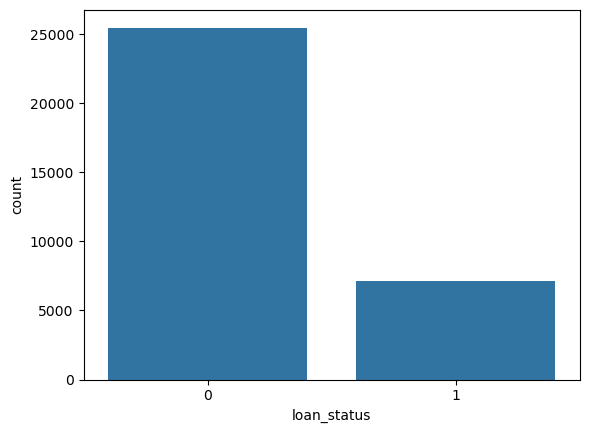

In [70]:
sns.countplot(x=df['loan_status'])

### Outlier Detection

In [71]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


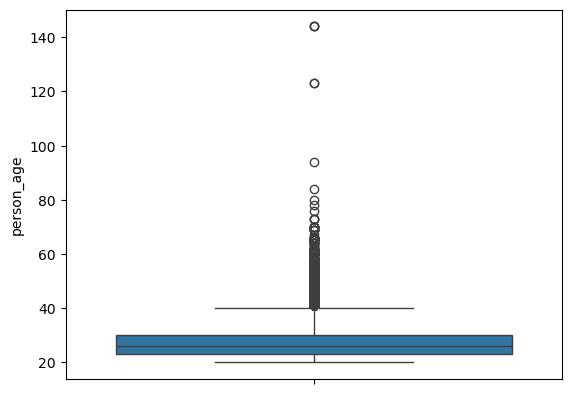

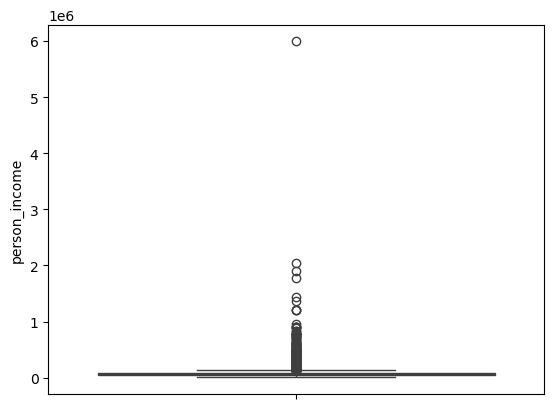

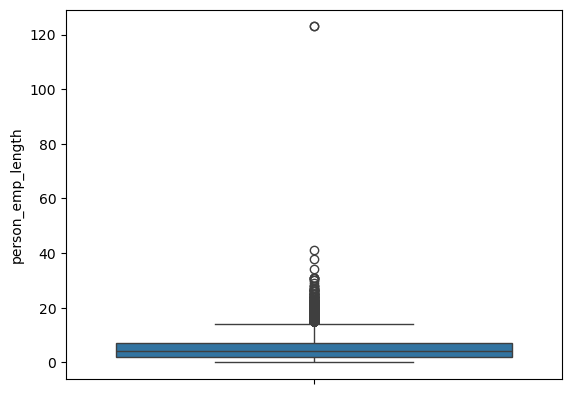

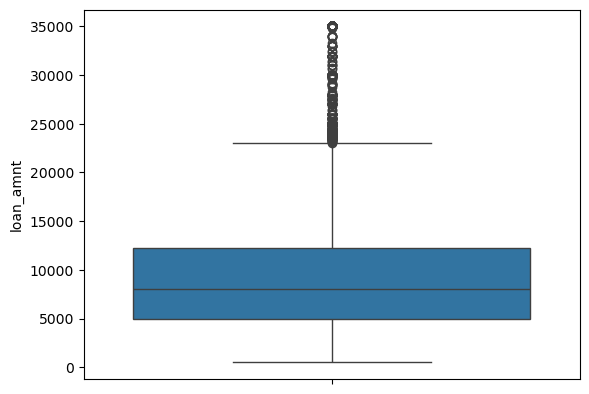

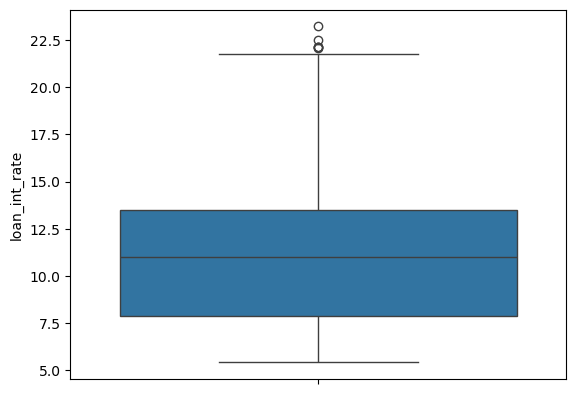

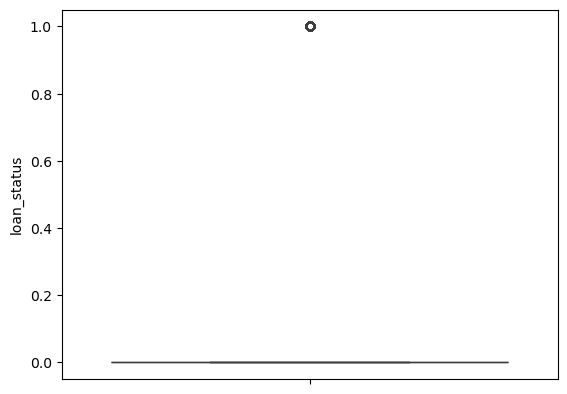

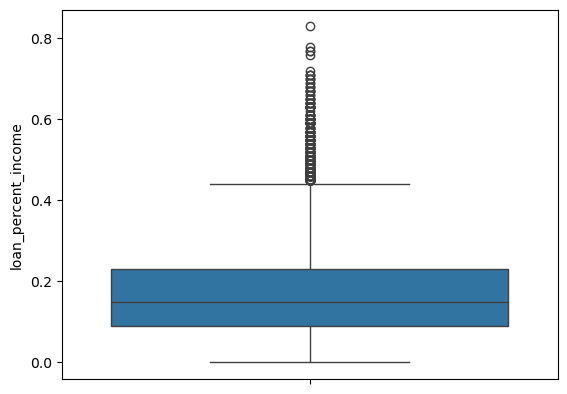

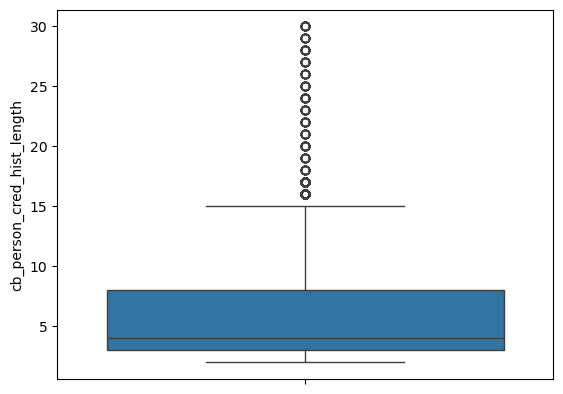

In [72]:
numerical_cols = df.select_dtypes(include='number').columns
for i in numerical_cols:
    sns.boxplot(df[i])
    plt.show()

In [73]:
(df['person_age']> 100).sum()

5

In [74]:
(df['person_emp_length']> 80).sum()

2

### Correlation check

<Axes: >

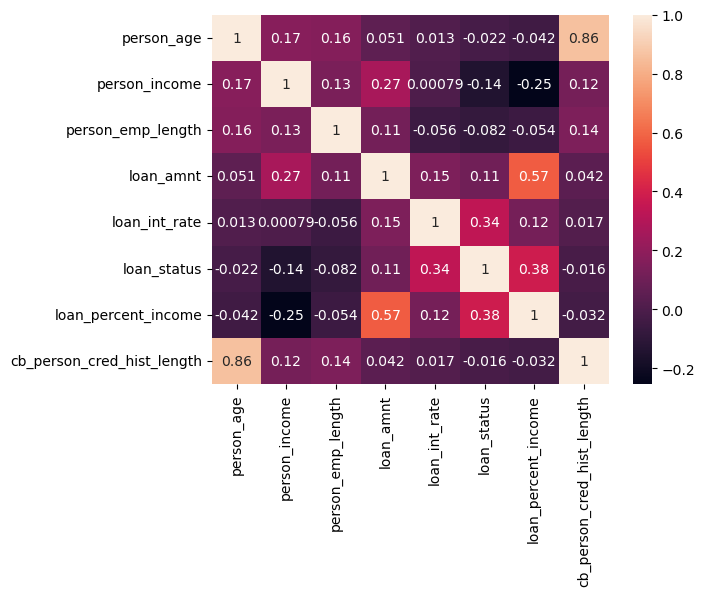

In [75]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

# 3. Data Cleaning

In [76]:
df_cleaned = df.copy()

# remove duplicates
print(f"no. of rows before deleting duplicates -> {df_cleaned.shape[0]}")
df_cleaned.drop_duplicates(inplace=True)
print(f"no. of rows after deleting duplicates -> {df_cleaned.shape[0]}")

no. of rows before deleting duplicates -> 32581
no. of rows after deleting duplicates -> 32416


In [77]:
# remove ages below 18 or above 100
df_cleaned = df_cleaned[df_cleaned['person_age'] >= 18]
df_cleaned = df_cleaned[df_cleaned['person_age'] <= 100]
df_cleaned.shape

(32411, 12)

In [78]:
# remove employement length greater than age or extreme outlier(>80)
df_cleaned = df_cleaned[df_cleaned['person_emp_length'] < df_cleaned['person_age']]
df_cleaned = df_cleaned[df_cleaned['person_emp_length'] < 80]
df_cleaned.shape

(31522, 12)

# 4. Features , Target and train-test-split

In [79]:
X = df_cleaned.drop(columns=['loan_status'])
y = df_cleaned['loan_status']

In [80]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [81]:
# specify numerical cols and categorical cols for operations on them like scaling, encoding etc.
numerical_cols = X.select_dtypes(include='number').columns
categorical_cols = df_cleaned.select_dtypes(include='object').columns

# 5. Handle Class Imbalance

In [82]:
# to handle class imbalance, we have methods like adding synthetic data, giving class weight
# we will give use class weight method by giving more weightage to minority class, and weight will be (count of majority class/count of minority class)
# bin count will give same values as value_counts give , number of class 1 and class 2, not used y_test to prevent data leakage
# our baseline model will be log reg and log reg already have hyperparameter for automatic class weight, we calculated this for XGBoost
maj, min = np.bincount(y_train)
class_weight = maj/min
# we will use this class weight during XGBoost model building

# 6. Data Preprocessing - Pipeline & Column Transformer

### Pre-processing for Logistic Regression(our baseline model)

In [83]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# column transformer helps to perform different pipeline on different type of columns like numerical, categorical etc. automatically(no manual effort)
preprocessor_lr = ColumnTransformer(
    transformers=[
        # pipeline for num columns
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numerical_cols),
        # pipeline for cat columns
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)

### Pre-processing for XGBoost

In [84]:
# in this scaling is not required
preprocessor_xg = ColumnTransformer(
    transformers=[
        # pipeline for num columns
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]), numerical_cols),
        # pipeline for cat columns
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)

# 7. Evaluation Helper Function

In [85]:
# one common function to check any model performance , so we dont have to write repetitive code every time
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, precision_recall_curve
def evaluate_model(model_name, model, X_test, y_test, threshold=None):
    
    y_pred_prob = model.predict_proba(X_test)[:,1]

    if threshold:
        y_pred = (y_pred_prob>threshold).astype(int)
    else:
        y_pred = model.predict(X_test)

    # metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    class_report = classification_report(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print(f"{model_name} Metrics: ")
    print(f"Accuracy: {accuracy:.2f} ")
    print(f"precision: {precision:.2f} ")
    print(f"recall: {recall:.2f} ")
    print(f"f1 score -> : {f1:.2f} ")
    print(f"class_report: {class_report} ")
    print(f"best Threshold: {threshold}")
    

    # plotting confusion matrix
    # fmt='d' means integer format
    sns.heatmap(cm, annot=True, fmt='d')
    plt.title(f"{model_name} Confusion Matrix")
    plt.ylabel("Actual Value")
    plt.xlabel("Predicted Value")
    plt.show()

    #plotting precision-recall-Curve
    precisions, recalls, threshold = precision_recall_curve(y_test, y_pred_prob)
    plt.plot(recalls, precisions)
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f"{model_name} Precision Recall Curve")
    plt.show()

# 8. Stratified Cross-Validation

In [86]:
# we'll perform stratified bcz stratified maintains class proportions, it's same as kfold just with maintaining class proprtion for unbalanced datasets
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
score = {'roc_auc':'roc_auc', 'accuracy':'accuracy', 'precision':'precision', 'recall':'recall', 'f1':'f1'}

In [87]:
# logistic regression model
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

In [88]:
# xgboost model
from xgboost import XGBClassifier
xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
        # n_jobs = -1: Uses all available CPU cores on your machine. This is usually the best choice for speeding up your model training significantly.
        # scale_pos_weight give weights to minority class
        n_estimator=300, max_depth=5, learning_rate=0.1,
        scale_pos_weight=class_weight, random_state=32
    ))
])

In [89]:
# validating
from sklearn.model_selection import cross_validate
for cv_name, pipe in [('Logistic Regression', lr_cv_pipeline),
                     ('XG Boost',xgb_cv_pipeline )]:
    cv_results = cross_validate(pipe, X_train, y_train, cv=cv, scoring=score, n_jobs=-1)

    print(cv_name)
    print(f"ROC-AUC: {cv_results['test_roc_auc'].mean()}")
    print(f"Accuracy: {cv_results['test_accuracy'].mean()}")
    print(f"Precision: {cv_results['test_precision'].mean()}")
    print(f"Recall: {cv_results['test_recall'].mean()}")
    print(f"F1 Score: {cv_results['test_f1'].mean()} \n")
    

Logistic Regression
ROC-AUC: 0.8705112830525306
Accuracy: 0.8115949542892269
Precision: 0.5448226008889892
Recall: 0.7781450872359963
F1 Score: 0.6408013995933108 

XG Boost
ROC-AUC: 0.9388000296700062
Accuracy: 0.9104966361456424
Precision: 0.7978050038979538
Recall: 0.7858585858585859
F1 Score: 0.7913675290846589 



# 9. BaseLine Model - Logistic Regression

In [90]:
baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced'))
])
baseline_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


baseline logistic model Metrics: 
Accuracy: 0.82 
precision: 0.56 
recall: 0.79 
f1 score -> : 0.65 
class_report:               precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305
 
best Threshold: None


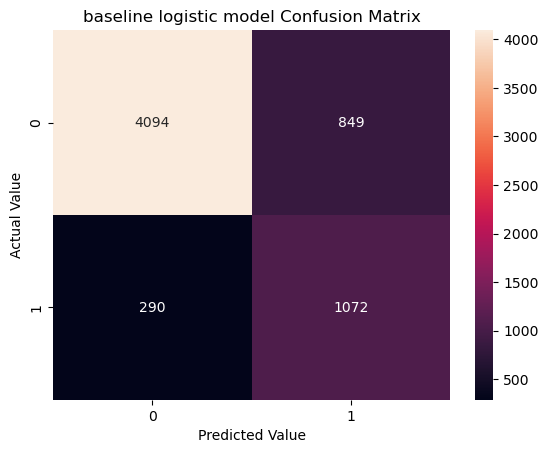

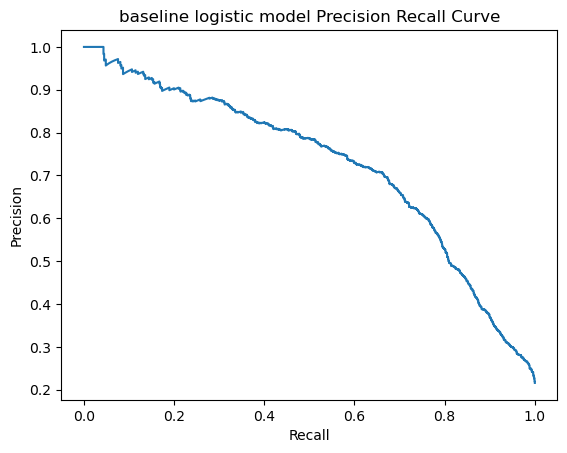

In [91]:
# evaluate
evaluate_model("baseline logistic model", baseline_model, X_test, y_test)

# 10. XGBoost Hyperparameter Tuning

In [92]:
xg_model = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(learning_rate=0.1, scale_pos_weight=class_weight, random_state=42))
])
xg_model.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


XG Boost Metrics: 
Accuracy: 0.92 
precision: 0.82 
recall: 0.79 
f1 score -> : 0.80 
class_report:               precision    recall  f1-score   support

           0       0.94      0.95      0.95      4943
           1       0.82      0.79      0.80      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.87      0.88      6305
weighted avg       0.92      0.92      0.92      6305
 
best Threshold: None


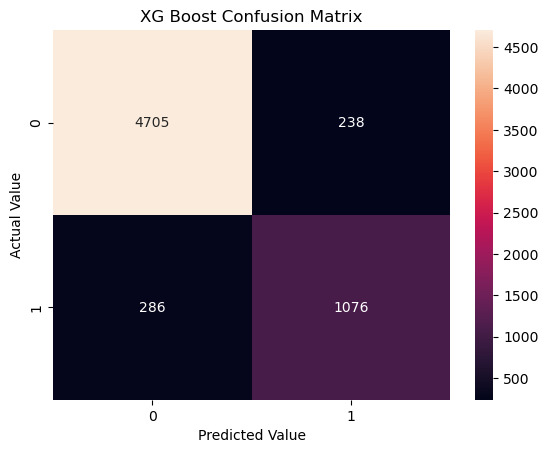

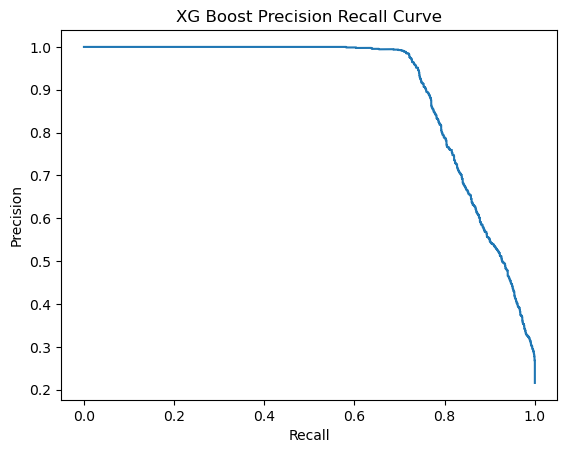

In [93]:
# evaluate
evaluate_model('XG Boost', xg_model, X_test, y_test)

In [94]:
from scipy.stats import uniform, randint
from sklearn.model_selection import RandomizedSearchCV
param_grid = {
    "classifier__n_estimators": randint(150,600),
    "classifier__max_depth": randint(3,9),
    "classifier__learning_rate": uniform(0.01,0.5),
    "classifier__subsample": uniform(0.6,0.4),
    "classifier__colsample_bytree": uniform(0.6,0.4),
    "classifier__min_child_weight": randint(1,10),
    "classifier__gamma": uniform(0,5)
}
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring='average_precision',
    n_jobs=-1,
    verbose=1
)
random_search.fit(X_train,y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


,estimator,"Pipeline(step...=None, ...))])"
,param_distributions,"{'classifier__colsample_bytree': <scipy.stats....001B9AAD32FF0>, 'classifier__gamma': <scipy.stats....001B9AAFE4DD0>, 'classifier__learning_rate': <scipy.stats....001B9AADD18E0>, 'classifier__max_depth': <scipy.stats....001B9A7FEA750>, ...}"
,n_iter,150
,scoring,'average_precision'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [95]:
print(f"best score is {random_search.best_score_:.2f}")
random_search.best_params_

best score is 0.90


{'classifier__colsample_bytree': 0.965639546250042,
 'classifier__gamma': 0.9392449506478667,
 'classifier__learning_rate': 0.13097889085248604,
 'classifier__max_depth': 5,
 'classifier__min_child_weight': 3,
 'classifier__n_estimators': 289,
 'classifier__subsample': 0.9484538033521428}

# 11. evaluate both model 

logistic regression Metrics: 
Accuracy: 0.82 
precision: 0.56 
recall: 0.79 
f1 score -> : 0.65 
class_report:               precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305
 
best Threshold: None


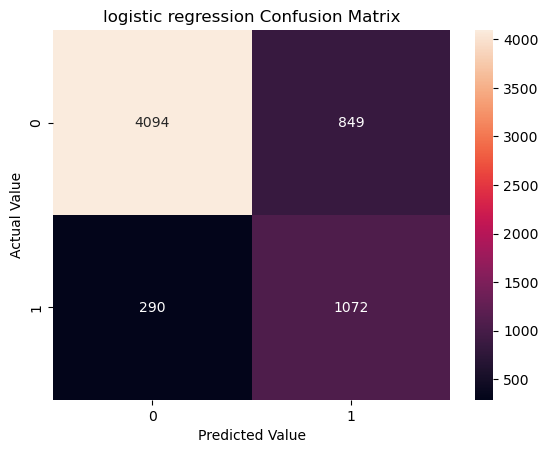

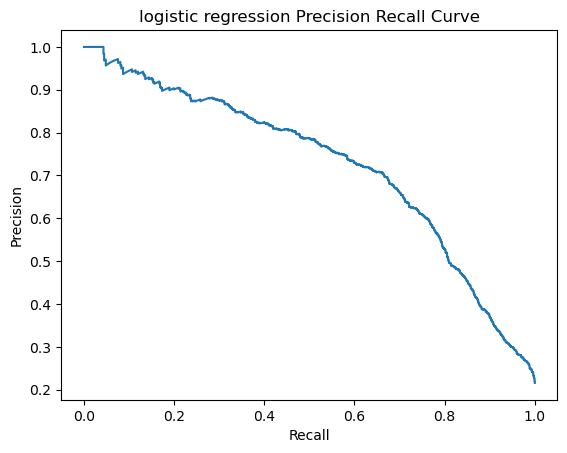

XG Boost Metrics: 
Accuracy: 0.92 
precision: 0.82 
recall: 0.81 
f1 score -> : 0.82 
class_report:               precision    recall  f1-score   support

           0       0.95      0.95      0.95      4943
           1       0.82      0.81      0.82      1362

    accuracy                           0.92      6305
   macro avg       0.89      0.88      0.88      6305
weighted avg       0.92      0.92      0.92      6305
 
best Threshold: None


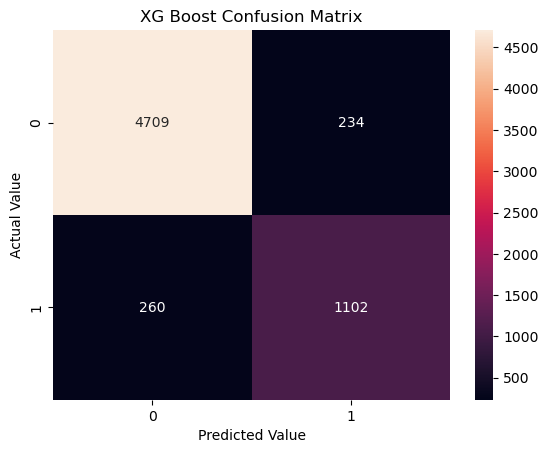

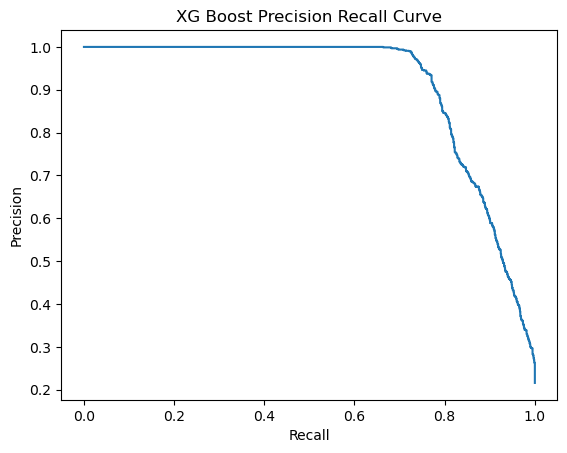

In [96]:
evaluate_model("logistic regression", baseline_model, X_test, y_test)
evaluate_model("XG Boost", random_search, X_test, y_test)

# 12. Optimizing the Classification Threshold

XGBoost Metrics: 
Accuracy: 0.94 
precision: 0.93 
recall: 0.77 
f1 score -> : 0.84 
class_report:               precision    recall  f1-score   support

           0       0.94      0.99      0.96      4943
           1       0.93      0.77      0.84      1362

    accuracy                           0.94      6305
   macro avg       0.94      0.88      0.90      6305
weighted avg       0.94      0.94      0.94      6305
 
best Threshold: 0.6478298306465149


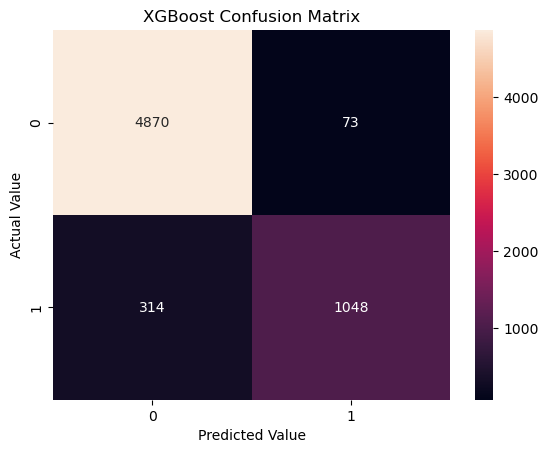

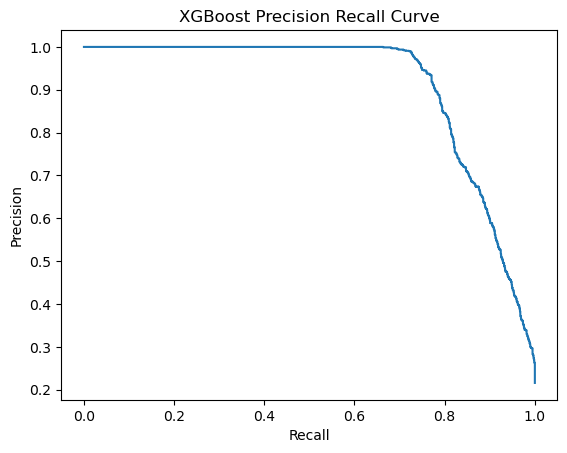

In [97]:
best_model = random_search.best_estimator_
#Get the prob. of class 1 from XGBoost
prob = best_model.predict_proba(X_test)[:,1]

#For each threshold calculate Precision and Recall
precisions, recalls, thresholds = precision_recall_curve(y_test,prob)

#Calculate F1 score for each threshold
f1 = 2 * (precisions*recalls) / (precisions + recalls + 1e-9)

#Get the threshold that produces the highest f1-score
# arg max gives the index of highest f1
best = np.argmax(f1[:-1])
best_threshold = thresholds[best]

#Evaluate the XGBoost model using that threshold.
evaluate_model("XGBoost", best_model, X_test, y_test, best_threshold)

# 13. Probability Calibration

In [98]:
# Probability calibration checks whether the probabilities predicted by a model match what happens in reality.
# Calibration individual person ke outcome ki guarantee nahi hai. Yeh bahut saare similar predictions ke group par check hota hai.
# Two common methods for Calibration are: 1. Sigmoid (Platt scaling) (used for small-medium data) 2. Isotonic regression (usually with more data)

# 1. calibrated XGBoost model
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
calibrated_model = CalibratedClassifierCV(
    estimator=best_model,
    method='sigmoid',
    cv=5
)
calibrated_model.fit(X_train,y_train)

,estimator,"Pipeline(step...=None, ...))])"
,method,'sigmoid'
,cv,5
,n_jobs,None
,ensemble,'auto'
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False


In [99]:
# 2. get porbability of uncalibrated model and calibrated model
uncalibrated = best_model.predict_proba(X_test)[:,1]
calibrated = calibrated_model.predict_proba(X_test)[:,1]

In [100]:
# 3. get calibration curves
actual_uncal, pred_uncal = calibration_curve(y_test, uncalibrated, n_bins=10)
actual_cal, pred_cal = calibration_curve(y_test, calibrated, n_bins=10)

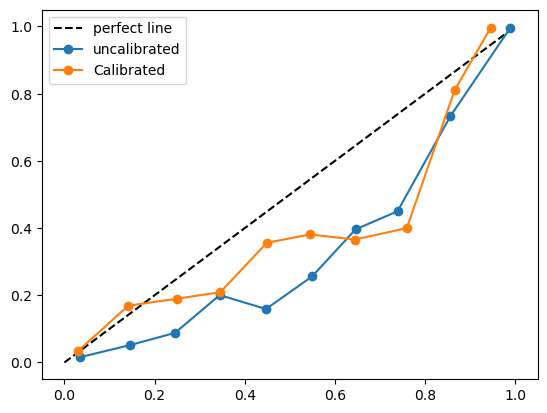

In [101]:
# 4. Plot

# perfect line for comparision -
plt.plot([0,1],[0,1], 'k--', label='perfect line')

plt.plot(
    pred_uncal,
    actual_uncal,
    'o-',
    label ='uncalibrated'
)
plt.plot(
    pred_cal,
    actual_cal,
    'o-',
    label ='Calibrated'
)
plt.legend()

Calibrated XGB Metrics: 
Accuracy: 0.93 
precision: 0.92 
recall: 0.77 
f1 score -> : 0.83 
class_report:               precision    recall  f1-score   support

           0       0.94      0.98      0.96      4943
           1       0.92      0.77      0.83      1362

    accuracy                           0.93      6305
   macro avg       0.93      0.87      0.90      6305
weighted avg       0.93      0.93      0.93      6305
 
best Threshold: None


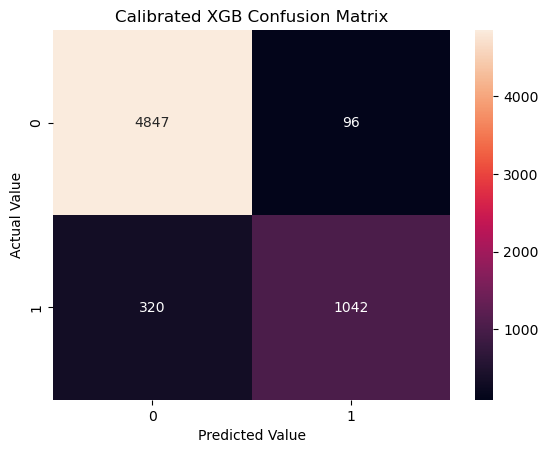

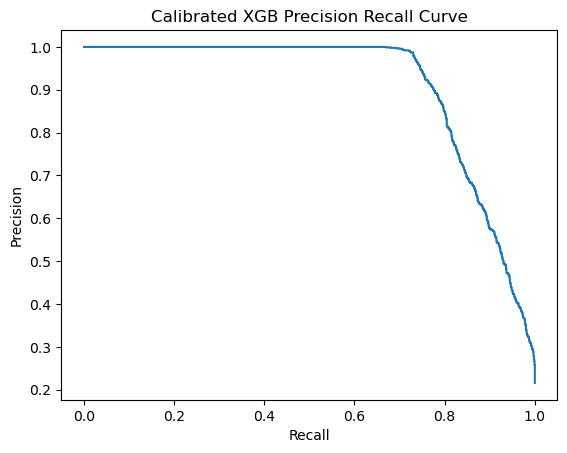

In [102]:
evaluate_model('Calibrated XGB', calibrated_model, X_test, y_test)

# 14. SHAP Interpretation — Global & Local
- SHapley Additive exPlanations
- SHAP explains how much each feature contributes to a model's prediction.
- It is a way of explaining a "black box" model.

In [103]:
# 1. import shap
import shap

# 2. get the trained model out of pipeline
xgb_classifier = best_model.named_steps['classifier']

# 3. transform the test data because we have seperated pipeline steps so now we need to do it manually
X_test_transformed = best_model.named_steps['preprocessor'].transform(X_test)

# 4. get features names after one hot encoding, so plots are readable
feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()

# 5. convert to a dataframe for a cleaner shap plots
X_test_df = pd.DataFrame(X_test_transformed, columns = feature_names)

# 6. create shap explainer built for tree based model
explainer = shap.TreeExplainer(xgb_classifier)

# 7. Calculate SHAP values for every row in the test set ( contributions )
shap_values = explainer.shap_values(X_test_df)

## Global Explanations
- This shows which features matter most overall.- 
It also shows if a feature increases or decreases risk.

1. Feature order = importance
2. Left vs right = direction of impact
3. Color = original feature value
 - Red/pink: high feature value.
 - Blue: low feature value.
4. Spread = variation in impact

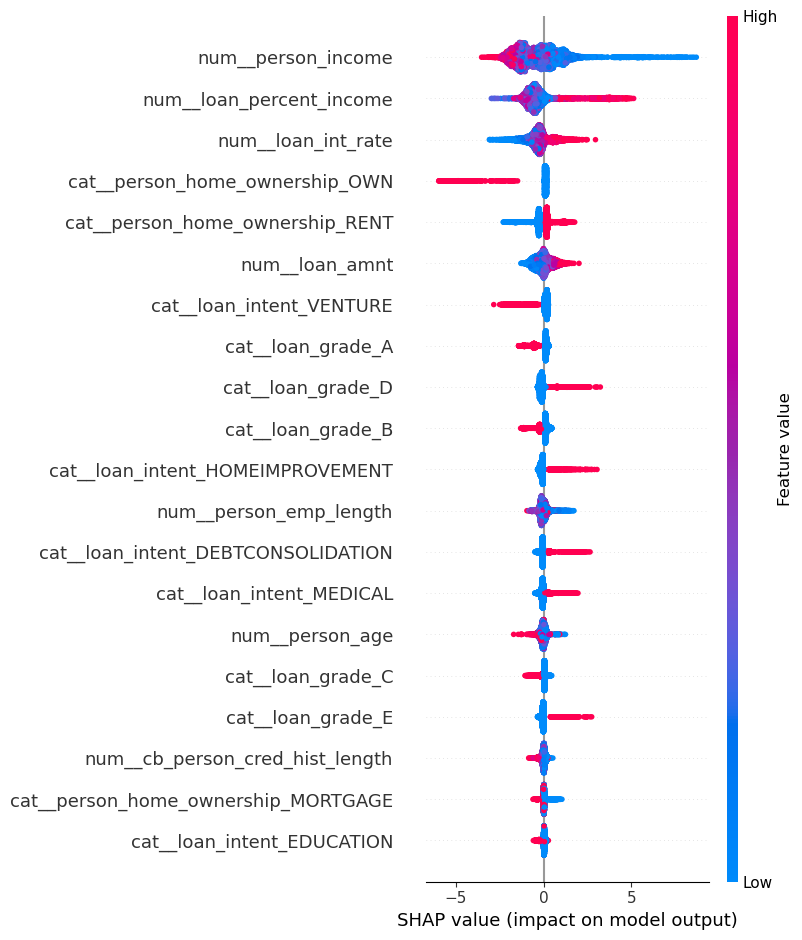

In [104]:
shap.summary_plot(shap_values, X_test_df)

## Local Explanations
- This shows why one specific applicant got their score.- 
It breaks the score down feature by feature.

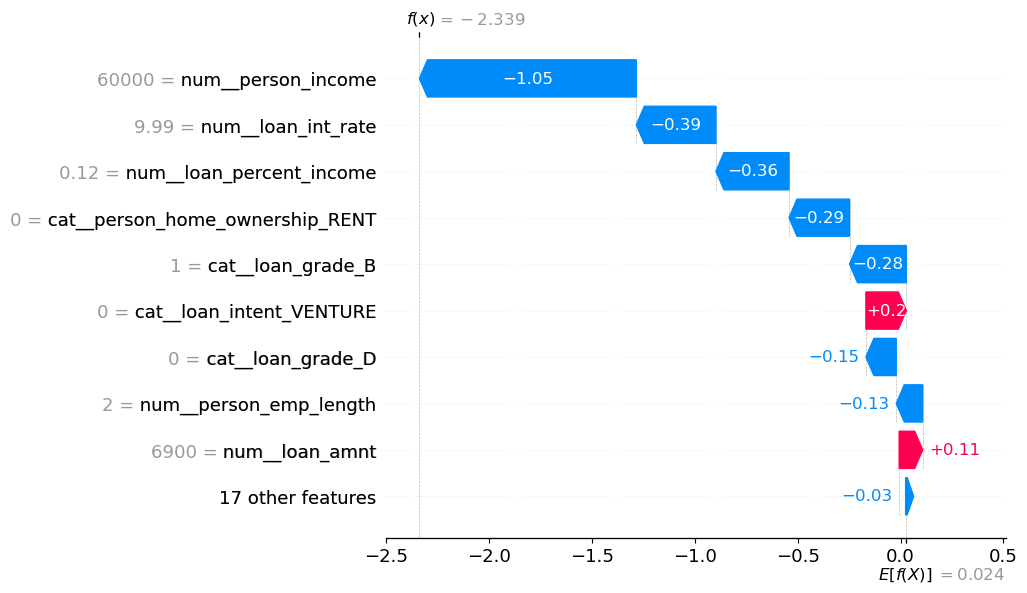

In [105]:
# 1. pick one sample to explain, ex - 5th applicant
row_index = 5

# 2. Draw a waterfall plot showing how each feature pushed the prediction up or down.
shap.plots.waterfall(
    shap.Explanation(
        # shap_values(feature contributions we calculated)
        values = shap_values[row_index],
        # model prediction
        base_values = explainer.expected_value,
        # actual data of that row
        data = X_test_df.iloc[row_index]
    )
)


# 15. threshold of Calibrated Model

Calibrated XGBoost Metrics: 
Accuracy: 0.94 
precision: 0.99 
recall: 0.72 
f1 score -> : 0.84 
class_report:               precision    recall  f1-score   support

           0       0.93      1.00      0.96      4943
           1       0.99      0.72      0.84      1362

    accuracy                           0.94      6305
   macro avg       0.96      0.86      0.90      6305
weighted avg       0.94      0.94      0.93      6305
 
best Threshold: 0.8206455707550049


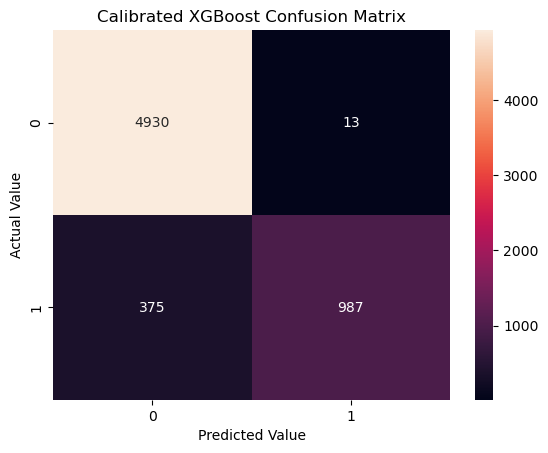

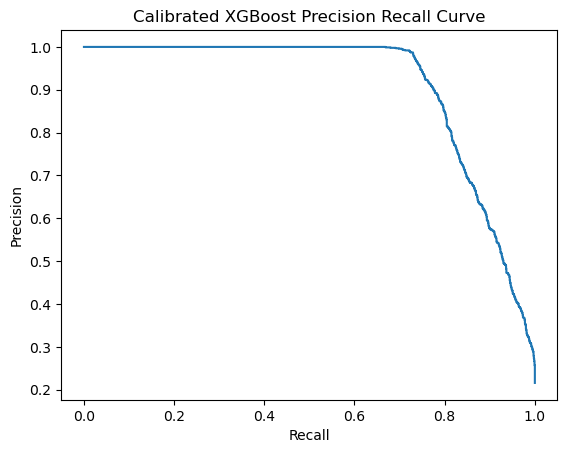

In [106]:
prob2 = calibrated_model.predict_proba(X_test)[:,1]

#For each threshold calculate Precision and Recall
precisions2, recalls2, thresholds2 = precision_recall_curve(y_test,prob2)

#Calculate F1 score for each threshold
f1_ = 2 * (precisions2*recalls2) / (precisions2 + recalls2 + 1e-9)

#Get the threshold that produces the highest f1-score
# arg max gives the index of highest f1
best2 = np.argmax(f1_[:-1])
best_threshold2 = thresholds[best2]

#Evaluate the XGBoost model using that threshold.
evaluate_model("Calibrated XGBoost", calibrated_model, X_test, y_test, best_threshold2)

# 16. Save the Final Model

In [107]:
import joblib
joblib.dump(calibrated_model,'credit_risk_model.pkl')

['credit_risk_model.pkl']

In [108]:
joblib.dump(best_threshold2,'best_threshold.pkl')

['best_threshold.pkl']